# Puntos 6 y 7 – Evapotranspiración potencial (Hargreaves-Samani) y real (Budyko)
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

**Punto 6.** ETP media multianual con Hargreaves-Samani (Anexos 2 y 3):

$$ETP_d = 0.0023\,R_a^*\,(T_{med}+17.8)\,\sqrt{T_{max}-T_{min}}$$

La radiación extraterrestre $R_a$ se calcula **para la latitud de cada celda** y para el día representativo de cada
mes (Anexo 3.9). Así se obtiene la ETP de cada mes, $ETP_m = ETP_{d,m}\,N_d$, y la anual es la suma de los 12 meses.

**Punto 7.** ETR de largo plazo con Budyko:

$$\phi = \frac{ETP}{P}, \qquad ETR = P\left[\phi\,\tanh\!\left(\frac{1}{\phi}\right)\left(1-e^{-\phi}\right)\right]^{1/2}$$

> En el enunciado la fórmula aparece como "tanh tanh"; es un error de edición. La ecuación de Budyko (1974) lleva
> **una sola** tangente hiperbólica, como está arriba.

**Archivos en la misma carpeta de este notebook:**
- `Tmax.tif`, `Tmin.tif`, `Tmed.tif` (punto 5)
- `P_IDEAM_anual.tif` (punto 3)
- `cuenca_cauca.gpkg` (punto 2); `rio_principal.gpkg` es opcional

**Salidas:** `ETP_anual.tif`, `ETP_mensual.tif` (12 bandas), `phi_IDEAM.tif`, `ETR_IDEAM.tif`, `R_IDEAM.tif`.

## 0. Instalación de librerías
Solo si no las instaló antes. Después de instalar, reinicie el kernel.

In [1]:
%pip install numpy pandas matplotlib geopandas rasterio pyproj shapely

Note: you may need to restart the kernel to use updated packages.


## 1. Librerías, parámetros y funciones de apoyo

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

pd.set_option("display.width", 200)

# ----------------------------- PARÁMETROS -----------------------------
CRS = "EPSG:3116"
CUENCA = "cuenca_cauca.gpkg"
RIO = "rio_principal.gpkg"
TMED_DESDE = "promedio"   # "promedio": Tmed = (Tmax + Tmin)/2, como indica el enunciado | "regresion": Tmed.tif
P_ANUAL = "P_IDEAM_anual.tif"
SUFIJO = "IDEAM"
# ----------------------------------------------------------------------

MESES = ["ENE", "FEB", "MAR", "ABR", "MAY", "JUN", "JUL", "AGO", "SEP", "OCT", "NOV", "DIC"]
DIA_JULIANO = [15, 45, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349]     # Anexo 3.9
DIAS_MES = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
GSC = 0.0820                                                                  # MJ m-2 min-1

In [3]:
# ----------------------- Funciones de apoyo SIG -----------------------
import rasterio
from rasterio import features
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from pyproj import Transformer
from shapely.geometry import shape
from shapely.ops import unary_union


def leer_raster(ruta):
    # Devuelve (arreglo enmascarado, info). Si el archivo tiene varias bandas: arreglo (bandas, filas, columnas)
    with rasterio.open(ruta) as src:
        arr = src.read(masked=True).astype("float64")
        info = {"transform": src.transform, "crs": src.crs, "shape": (src.height, src.width),
                "profile": src.profile.copy()}
    return (arr[0] if arr.shape[0] == 1 else arr), info


def guardar_raster(ruta, arr, info, nodata=-9999.0, descripciones=None, dtype="float32"):
    a = np.ma.masked_invalid(np.ma.asarray(arr, dtype="float64"))
    if a.ndim == 2:
        a = a[None]
    perfil = info["profile"].copy()
    perfil.update(driver="GTiff", dtype=dtype, nodata=nodata, count=a.shape[0], compress="lzw")
    with rasterio.open(ruta, "w", **perfil) as dst:
        dst.write(a.filled(nodata).astype(dtype))
        for i, d in enumerate(descripciones or [], start=1):
            dst.set_band_description(i, d)


def coords_celdas(info):
    # Coordenadas (x, y) del centro de cada celda, en el SRC del ráster
    T = info["transform"]
    filas, cols = np.indices(info["shape"])
    return T.a * (cols + 0.5) + T.b * (filas + 0.5) + T.c, T.d * (cols + 0.5) + T.e * (filas + 0.5) + T.f


def a_lonlat(x, y, crs):
    lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform(np.asarray(x), np.asarray(y))
    return np.asarray(lon), np.asarray(lat)


def de_lonlat(lon, lat, crs):
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(np.asarray(lon), np.asarray(lat))
    return np.asarray(x), np.asarray(y)


def remuestrear_a_grilla(arr, lon, lat, info, metodo="bilinear"):
    # Lleva un campo en grilla regular lon/lat (2D o 3D con el tiempo primero) a la grilla del DEM
    arr = np.asarray(arr, dtype="float64")
    if lat[0] < lat[-1]:                       # filas de norte a sur
        arr, lat = arr[..., ::-1, :], lat[::-1]
    dx, dy = abs(lon[1] - lon[0]), abs(lat[1] - lat[0])
    src_T = from_origin(lon.min() - dx / 2, lat.max() + dy / 2, dx, dy)
    capas = arr if arr.ndim == 3 else arr[None]
    salida = np.full((capas.shape[0],) + info["shape"], np.nan)
    for k in range(capas.shape[0]):
        reproject(source=np.ascontiguousarray(capas[k]), destination=salida[k], src_transform=src_T,
                  src_crs="EPSG:4326", src_nodata=np.nan, dst_transform=info["transform"], dst_crs=info["crs"],
                  dst_nodata=np.nan, resampling=getattr(Resampling, metodo))
    return salida if arr.ndim == 3 else salida[0]


def mascara_geometria(geom, info):
    # True en las celdas cuyo centro cae dentro de la geometría
    return features.geometry_mask([geom], out_shape=info["shape"], transform=info["transform"], invert=True)


def poligonizar(mascara, info):
    geoms = [shape(g) for g, v in features.shapes(mascara.astype("uint8"), mask=mascara,
                                                    transform=info["transform"]) if v == 1]
    return unary_union(geoms)

In [4]:
def decorar(ax, titulo, ext, cuenca, rio=None):
    # Límite de la cuenca, río, flecha de norte, barra de escala y SRC
    cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
    if rio is not None:
        rio.plot(ax=ax, color="#08306b", lw=1.0)
    ax.annotate("", xy=(0.93, 0.93), xytext=(0.93, 0.84), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.5))
    ax.text(0.93, 0.945, "N", transform=ax.transAxes, ha="center", fontsize=12, fontweight="bold")
    x0 = ext[0] + 0.06 * (ext[1] - ext[0]); y0 = ext[2] + 0.04 * (ext[3] - ext[2])
    ax.plot([x0, x0 + 50000], [y0, y0], "k-", lw=3)
    ax.text(x0 + 25000, y0 + 0.012 * (ext[3] - ext[2]), "50 km", ha="center", fontsize=8)
    ax.set_title(titulo, fontsize=11)
    ax.text(0.02, 0.005, "MAGNA-SIRGAS / Colombia Bogotá zone (EPSG:3116)", transform=ax.transAxes, fontsize=7,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.ticklabel_format(style="plain"); ax.tick_params(labelsize=7)
    ax.locator_params(axis="x", nbins=4)
    ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")


def extension(info):
    T = info["transform"]; h, w = info["shape"]
    return [T.c, T.c + T.a * w, T.f + T.e * h, T.f]


def mapa(arr, info, titulo, etiqueta, cuenca, rio=None, cmap="viridis", archivo=None, vmin=None, vmax=None, ax=None):
    ext = extension(info)
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(6, 9))
    im = ax.imshow(arr, extent=ext, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    if propio:
        plt.colorbar(im, ax=ax, shrink=0.6, label=etiqueta)
    decorar(ax, titulo, ext, cuenca, rio)
    if propio:
        fig.tight_layout()
        if archivo:
            fig.savefig(archivo, dpi=200)
        plt.show()
    return im

cuenca = gpd.read_file(CUENCA).to_crs(CRS)
rio = gpd.read_file(RIO).to_crs(CRS) if os.path.exists(RIO) else None

## 2. Lectura de los mapas de temperatura y precipitación

In [5]:
tmax, info = leer_raster("Tmax.tif")
tmin, _ = leer_raster("Tmin.tif")
tmed = (tmax + tmin) / 2 if TMED_DESDE == "promedio" else leer_raster("Tmed.tif")[0]
P, info_p = leer_raster(P_ANUAL)
assert P.shape == tmax.shape, "P y T deben estar en la misma grilla (la del DEM_cuenca.tif)"
mascara = np.ma.getmaskarray(tmax) | np.ma.getmaskarray(tmin) | np.ma.getmaskarray(P)
tmax, tmin, tmed, P = (np.ma.masked_array(a, mask=mascara) for a in (tmax, tmin, tmed, P))
ext = extension(info)
celda_km2 = abs(info["transform"].a * info["transform"].e) / 1e6
print(f"Celdas: {(~mascara).sum():,} | área {(~mascara).sum() * celda_km2:,.0f} km²")
print(f"Tmed usada: {'(Tmax+Tmin)/2' if TMED_DESDE == 'promedio' else 'regresión del punto 4'} | "
      f"media de la cuenca {tmed.mean():.1f} °C")

Celdas: 40,633 | área 35,283 km²
Tmed usada: (Tmax+Tmin)/2 | media de la cuenca 18.8 °C


## 3. Radiación extraterrestre $R_a$ (Anexo 3)
Para cada día juliano $J$ y latitud $\varphi$:

- $d_r = 1 + 0.033\cos(2\pi J/365)$
- $\delta = 0.409\,\sin(2\pi J/365 - 1.39)$
- $\omega_s = \arccos[-\tan\varphi\,\tan\delta]$
- $R_a = \frac{1440}{\pi} G_{sc}\, d_r\,[\omega_s \sin\varphi \sin\delta + \cos\varphi\cos\delta\sin\omega_s]$ en MJ m⁻² día⁻¹
- $R_a^* = 0.408\,R_a$ en mm/día

La cuenca va de unos 2° N a 7° N, así que se calcula $R_a$ con la latitud de cada celda.

Latitud de la cuenca: 2.10° a 7.16° N (media 4.49°)


,J,Ra (MJ/m²/día) a 2.1°N,Ra (MJ/m²/día) a 4.5°N,Ra (MJ/m²/día) a 7.2°N,Ra* (mm/día) a 4.5°N
ENE,15,35.33,34.34,33.17,14.01
FEB,45,36.86,36.19,35.37,14.77
MAR,74,37.78,37.57,37.26,15.33
ABR,105,37.11,37.43,37.71,15.27
MAY,135,35.43,36.13,36.85,14.74
JUN,166,34.24,35.11,36.03,14.33
JUL,196,34.60,35.41,36.24,14.45
AGO,227,36.13,36.61,37.09,14.94
SEP,258,37.28,37.28,37.21,15.21
OCT,288,36.96,36.45,35.82,14.87


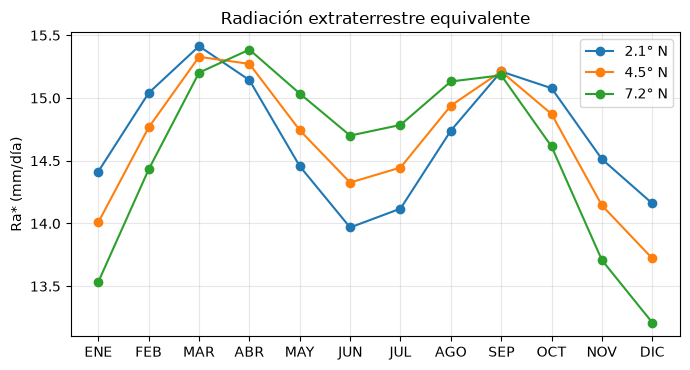

In [6]:
def radiacion_extraterrestre(lat_grados, J):
    # Devuelve (Ra en MJ m-2 día-1, Ra* en mm/día) - Anexo 3
    phi = np.deg2rad(lat_grados)
    dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
    delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    Ra = (1440 / np.pi) * GSC * dr * (ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws))
    return Ra, 0.408 * Ra


# Latitud del centro de cada celda
xc, yc = coords_celdas(info)
_, lat = a_lonlat(xc, yc, info["crs"])
lat = np.ma.masked_array(lat, mask=mascara)
print(f"Latitud de la cuenca: {lat.min():.2f}° a {lat.max():.2f}° N (media {lat.mean():.2f}°)")

# Tabla de Ra por mes para la latitud media y las extremas (sirve para el informe)
tabla_ra = pd.DataFrame({
    "J": DIA_JULIANO,
    **{f"Ra (MJ/m²/día) a {l:.1f}°N": radiacion_extraterrestre(l, np.array(DIA_JULIANO))[0]
       for l in (lat.min(), lat.mean(), lat.max())},
    f"Ra* (mm/día) a {lat.mean():.1f}°N": radiacion_extraterrestre(lat.mean(), np.array(DIA_JULIANO))[1],
}, index=MESES)
display(tabla_ra.round(2))

fig, ax = plt.subplots(figsize=(7, 3.8))
for l in (lat.min(), lat.mean(), lat.max()):
    ax.plot(MESES, radiacion_extraterrestre(l, np.array(DIA_JULIANO))[1], marker="o", label=f"{l:.1f}° N")
ax.set_ylabel("Ra* (mm/día)"); ax.set_title("Radiación extraterrestre equivalente")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("fig_Ra_mensual.png", dpi=200)
plt.show()

## 4. ETP de Hargreaves-Samani: mensual y anual (punto 6)
$$ETP_{d,m} = 0.0023\,R^*_{a,m}\,(T_{med}+17.8)\sqrt{T_{max}-T_{min}}, \qquad ETP_m = ETP_{d,m}\,N_d, \qquad ETP_{anual} = \sum_{m=1}^{12} ETP_m$$

Las temperaturas son medias anuales (punto 5); lo que cambia de un mes a otro es $R_a$. También se calcula la versión
simplificada del punto 6 (ETP diaria con el $R_a$ medio del año × 365), para mostrar que la diferencia es mínima.

In [7]:
rango = np.sqrt(np.clip(tmax - tmin, 0, None))
etp_mensual = []
for J, nd in zip(DIA_JULIANO, DIAS_MES):
    _, ra_mm = radiacion_extraterrestre(lat, J)
    etp_mensual.append(0.0023 * ra_mm * (tmed + 17.8) * rango * nd)
etp_mensual = np.ma.stack(etp_mensual)                 # (12, filas, columnas) en mm/mes
ETP = etp_mensual.sum(axis=0)                           # mm/año

ra_medio = np.ma.mean(np.ma.stack([radiacion_extraterrestre(lat, J)[1] for J in DIA_JULIANO]), axis=0)
ETP_365 = 0.0023 * ra_medio * (tmed + 17.8) * rango * 365

guardar_raster("ETP_anual.tif", ETP, info)
guardar_raster("ETP_mensual.tif", etp_mensual, info, descripciones=MESES)

ciclo_etp = pd.Series([m.mean() for m in etp_mensual], index=MESES, name="ETP (mm/mes)")
print(f"ETP media anual de la cuenca: {ETP.mean():,.0f} mm/año  (mín {ETP.min():,.0f}, máx {ETP.max():,.0f})")
print(f"Versión simplificada (ETP diaria × 365): {ETP_365.mean():,.0f} mm/año "
      f"(diferencia {100 * (ETP_365.mean() / ETP.mean() - 1):+.2f} %)")
display(ciclo_etp.round(1).to_frame().T)

ETP media anual de la cuenca: 1,399 mm/año  (mín 412, máx 1,919)
Versión simplificada (ETP diaria × 365): 1,400 mm/año (diferencia +0.01 %)


,ENE,FEB,MAR,ABR,MAY,JUN,JUL,AGO,SEP,OCT,NOV,DIC
ETP (mm/mes),113.6,108.2,124.4,120.0,119.7,112.6,117.3,121.3,119.5,120.7,111.0,111.3


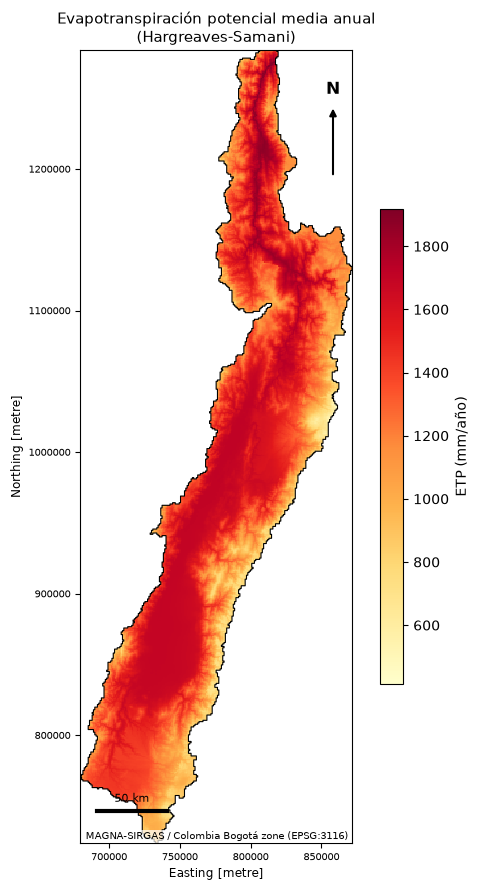

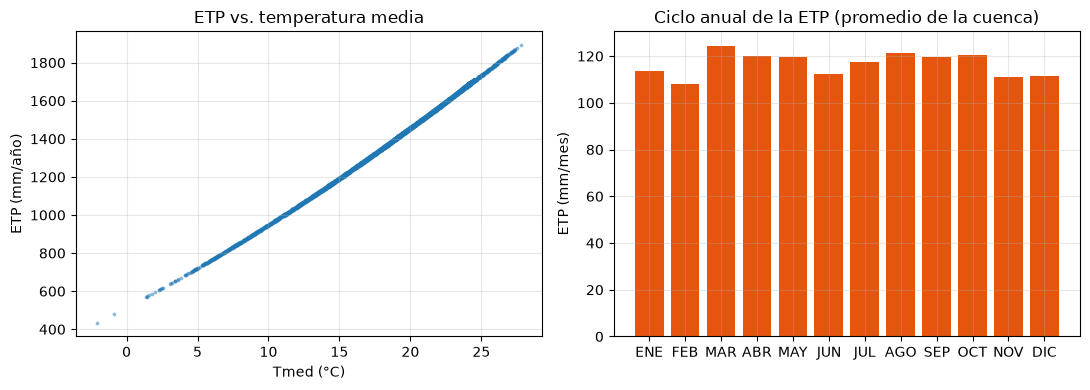

In [8]:
mapa(ETP, info, "Evapotranspiración potencial media anual\n(Hargreaves-Samani)", "ETP (mm/año)", cuenca, rio,
     cmap="YlOrRd", archivo="fig_mapa_ETP.png")

# ETP frente a la elevación (implícita en la temperatura) y frente a la latitud
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
sel = np.random.default_rng(0).choice((~mascara).sum(), size=min(5000, (~mascara).sum()), replace=False)
axs[0].scatter(tmed.compressed()[sel], ETP.compressed()[sel], s=3, alpha=0.4)
axs[0].set(xlabel="Tmed (°C)", ylabel="ETP (mm/año)", title="ETP vs. temperatura media")
axs[1].bar(MESES, ciclo_etp, color="#e6550d")
axs[1].set(ylabel="ETP (mm/mes)", title="Ciclo anual de la ETP (promedio de la cuenca)")
for a in axs: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig_ETP_analisis.png", dpi=200)
plt.show()

## 5. Índice de aridez y ETR de Budyko (punto 7)
- $\phi < 1$: zona **húmeda**. Hay más agua de la que la atmósfera puede evaporar; la ETR está limitada por la energía y tiende a la ETP.
- $\phi > 1$: zona **seca**. La ETR está limitada por el agua y tiende a P.

In [9]:
def budyko(P, ETP):
    phi = ETP / P
    return P * np.sqrt(phi * np.tanh(1 / phi) * (1 - np.exp(-phi))), phi


ETR, phi = budyko(P, ETP)
R = P - ETR
guardar_raster(f"phi_{SUFIJO}.tif", phi, info)
guardar_raster(f"ETR_{SUFIJO}.tif", ETR, info)
guardar_raster(f"R_{SUFIJO}.tif", R, info)

area = (~mascara).sum() * celda_km2
resumen = pd.DataFrame({
    "P (mm/año)": [P.mean()], "ETP (mm/año)": [ETP.mean()], "φ = ETP/P (promedio de celdas)": [phi.mean()],
    "φ con promedios de cuenca": [ETP.mean() / P.mean()], "ETR (mm/año)": [ETR.mean()], "ETR/P": [ETR.mean() / P.mean()],
    "R = P − ETR (mm/año)": [R.mean()], "Q equivalente (m³/s)": [R.mean() / 1000 * area * 1e6 / (365.25 * 86400)],
}, index=["Cuenca hasta Hidroituango"]).T
display(resumen.round(3))
print(f"Área con φ < 1 (húmeda): {100 * (phi < 1).sum() / phi.count():.1f} %  |  φ > 1 (seca): {100 * (phi > 1).sum() / phi.count():.1f} %")

,Cuenca hasta Hidroituango
P (mm/año),1990.343
ETP (mm/año),1399.435
φ = ETP/P (promedio de celdas),0.765
φ con promedios de cuenca,0.703
ETR (mm/año),1076.204
ETR/P,0.541
R = P − ETR (mm/año),914.140
Q equivalente (m³/s),1022.054


Área con φ < 1 (húmeda): 82.3 %  |  φ > 1 (seca): 17.7 %


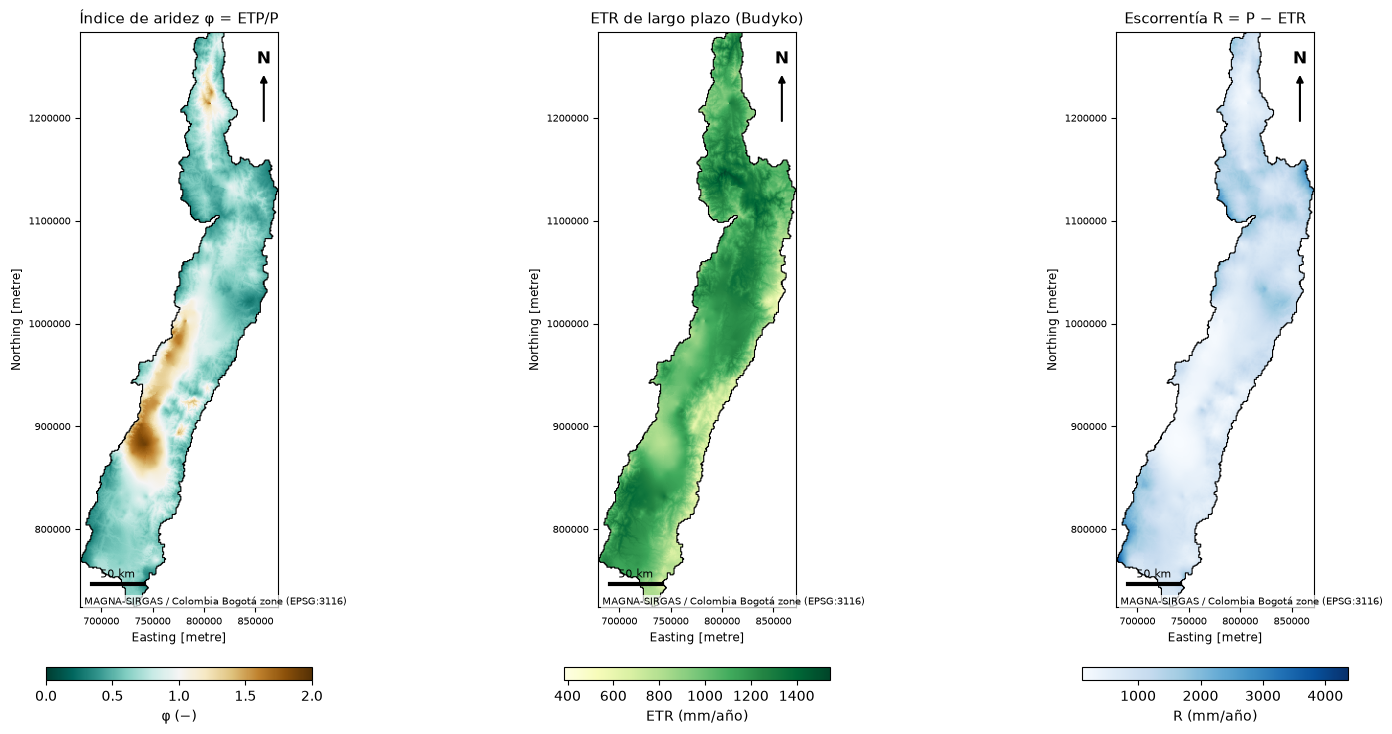

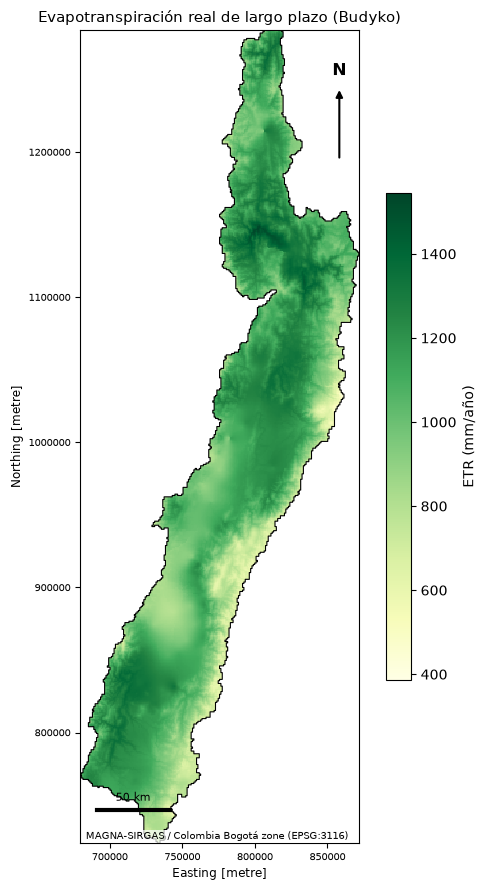

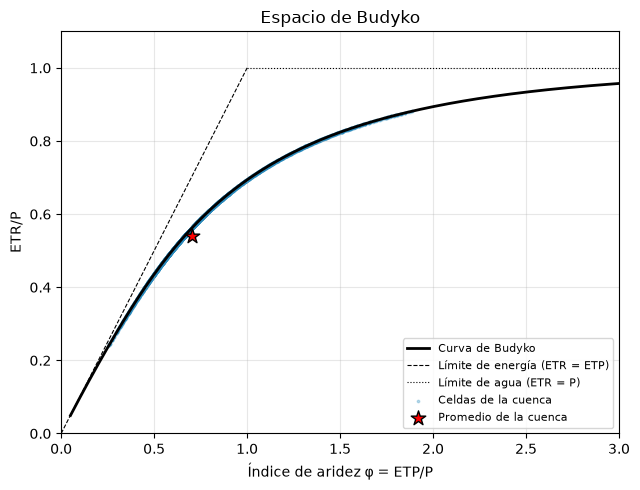

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 8))
ims = [mapa(phi, info, "Índice de aridez φ = ETP/P", "φ", cuenca, rio, cmap="BrBG_r", ax=axs[0], vmin=0, vmax=2),
       mapa(ETR, info, "ETR de largo plazo (Budyko)", "mm/año", cuenca, rio, cmap="YlGn", ax=axs[1]),
       mapa(R, info, "Escorrentía R = P − ETR", "mm/año", cuenca, rio, cmap="Blues", ax=axs[2])]
for ax, im, et in zip(axs, ims, ["φ (−)", "ETR (mm/año)", "R (mm/año)"]):
    plt.colorbar(im, ax=ax, shrink=0.5, orientation="horizontal", pad=0.08, label=et)
fig.tight_layout(); fig.savefig("fig_mapas_phi_ETR_R.png", dpi=200)
plt.show()

mapa(ETR, info, "Evapotranspiración real de largo plazo (Budyko)", "ETR (mm/año)", cuenca, rio, cmap="YlGn",
     archivo="fig_mapa_ETR.png")

# Espacio de Budyko: cada celda de la cuenca sobre la curva teórica
f = np.linspace(0.05, 3, 300)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(f, np.sqrt(f * np.tanh(1 / f) * (1 - np.exp(-f))), "k-", lw=2, label="Curva de Budyko")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Límite de energía (ETR = ETP)")
ax.plot([1, 3], [1, 1], "k:", lw=0.8, label="Límite de agua (ETR = P)")
ax.scatter(phi.compressed()[sel], (ETR / P).compressed()[sel], s=3, alpha=0.3, c="#2b8cbe", label="Celdas de la cuenca")
ax.scatter(ETP.mean() / P.mean(), ETR.mean() / P.mean(), s=120, marker="*", c="red", edgecolor="k", zorder=5,
           label="Promedio de la cuenca")
ax.set(xlabel="Índice de aridez φ = ETP/P", ylabel="ETR/P", xlim=(0, 3), ylim=(0, 1.1), title="Espacio de Budyko")
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig("fig_espacio_budyko.png", dpi=200)
plt.show()

## 6. Guía para el análisis (ajústela a sus números)
**ETP (punto 6)**
- La ETP de Hargreaves depende de la temperatura y de la radiación extraterrestre. Por eso es **mayor en las zonas
  bajas y cálidas** (fondo del valle y del cañón) y disminuye con la altura, siguiendo el mismo patrón del mapa de Tmed.
- El término $\sqrt{T_{max}-T_{min}}$ aproxima el efecto de la nubosidad: una amplitud térmica grande indica cielos
  más despejados y más radiación que llega a la superficie.
- Cerca del ecuador $R_a$ varía poco durante el año, con dos máximos alrededor de los equinoccios. Por eso el ciclo
  anual de la ETP es suave.
- **Limitación:** Hargreaves no tiene en cuenta la humedad ni el viento, y fue calibrado en zonas semiáridas. En los
  Andes húmedos tiende a sobrestimar o subestimar según la nubosidad real. Compare con la hoja de ETP del Excel del IDEAM.

**ETR de Budyko (punto 7)**
- La mayor parte de la cuenca tiene φ < 1 (húmeda): la ETR se acerca a la ETP y está **limitada por la energía**.
- Donde llueve poco (valle geográfico del Cauca, ~900–1.200 mm), φ se acerca o supera 1. Allí la ETR está **limitada
  por el agua** y una fracción mayor de la lluvia se evapora (ETR/P alto, poca escorrentía).
- En el norte muy lluvioso, cerca de Hidroituango, ETR/P es bajo y la mayor parte de la lluvia escurre.
- El mapa R = P − ETR anticipa cuáles subcuencas producen más caudal (punto 9).